In [1]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All libraries imported successfully!")

NumPy: 2.5.1
Pandas: 3.0.5
Scikit-learn: 1.9.0
All libraries imported successfully!


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [3]:
from sklearn.datasets import fetch_california_housing

In [4]:
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing()

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
print("Dataset shape:", data.data.shape)
print("Target shape:", data.target.shape)

Dataset shape: (20640, 8)
Target shape: (20640,)


In [6]:
print("Feature names:")
for feature in data.feature_names:
    print(feature)

Feature names:
MedInc
HouseAge
AveRooms
AveBedrms
Population
AveOccup
Latitude
Longitude


In [7]:
df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

df["Target"] = data.target

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   Target      20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [9]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Target        0
dtype: int64


In [10]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [11]:
X = data.data
y = data.target

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20640, 8)
y shape: (20640,)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 16512
Testing samples: 4128


In [13]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(
    y_train.reshape(-1, 1)
).ravel()

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [14]:
linear_model = LinearRegression()

print("Linear Regression model created.")

Linear Regression model created.


In [15]:
linear_model.fit(X_train, y_train)

print("Linear Regression training completed.")

Linear Regression training completed.


In [16]:
y_pred_linear = linear_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_linear[:10])

First 10 predictions:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


In [17]:
linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_r2 = r2_score(y_test, y_pred_linear)

print("Linear Regression")
print("-----------------------------")
print("MAE:", linear_mae)
print("MSE:", linear_mse)
print("R2 Score:", linear_r2)

Linear Regression
-----------------------------
MAE: 0.5332001304956978
MSE: 0.5558915986952426
R2 Score: 0.5757877060324521


In [18]:
poly = PolynomialFeatures(degree=2)

X_poly_train = poly.fit_transform(X_train)
X_poly_test = poly.transform(X_test)

print("Polynomial features created.")
print("Original number of features:", X_train.shape[1])
print("Polynomial number of features:", X_poly_train.shape[1])

Polynomial features created.
Original number of features: 8
Polynomial number of features: 45


In [19]:
poly_model = LinearRegression()

print("Polynomial Regression model created.")

Polynomial Regression model created.


In [20]:
poly_model.fit(X_poly_train, y_train)

print("Polynomial Regression training completed.")

Polynomial Regression training completed.


In [21]:
y_pred_poly = poly_model.predict(X_poly_test)

print("First 10 predictions:")
print(y_pred_poly[:10])

First 10 predictions:
[0.68783071 1.77122227 3.06395416 2.77396334 2.559257   1.91527822
 2.6269437  2.10991955 2.78388618 4.09723277]


In [22]:
poly_mae = mean_absolute_error(y_test, y_pred_poly)
poly_mse = mean_squared_error(y_test, y_pred_poly)
poly_r2 = r2_score(y_test, y_pred_poly)

print("Polynomial Regression")
print("-----------------------------")
print("MAE:", poly_mae)
print("MSE:", poly_mse)
print("R2 Score:", poly_r2)

Polynomial Regression
-----------------------------
MAE: 0.5161833692971959
MSE: 0.604538316538165
R2 Score: 0.5386643967063621


In [23]:
dt_model = DecisionTreeRegressor(
    random_state=42
)

print("Decision Tree Regression model created.")

Decision Tree Regression model created.


In [24]:
dt_model.fit(X_train, y_train)

print("Decision Tree Regression training completed.")

Decision Tree Regression training completed.


In [25]:
y_pred_dt = dt_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_dt[:10])

First 10 predictions:
[0.414   1.203   5.00001 2.17    2.257   1.664   2.217   1.74    2.772
 5.00001]


In [26]:
dt_mae = mean_absolute_error(y_test, y_pred_dt)
dt_mse = mean_squared_error(y_test, y_pred_dt)
dt_r2 = r2_score(y_test, y_pred_dt)

print("Decision Tree Regression")
print("-----------------------------")
print("MAE:", dt_mae)
print("MSE:", dt_mse)
print("R2 Score:", dt_r2)

Decision Tree Regression
-----------------------------
MAE: 0.4541711942829458
MSE: 0.494255717630063
R2 Score: 0.622823312540521


In [27]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

print("Random Forest Regression model created.")

Random Forest Regression model created.


In [28]:
rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [29]:
y_pred_rf = rf_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_rf[:10])

First 10 predictions:
[0.50809   0.75064   4.9582073 2.50172   2.24778   1.64329   2.34423
 1.66199   2.7341705 4.9178088]


In [30]:
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_mse = mean_squared_error(y_test, y_pred_rf)
rf_r2 = r2_score(y_test, y_pred_rf)

print("Random Forest Regression")
print("-----------------------------")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("R2 Score:", rf_r2)

Random Forest Regression
-----------------------------
MAE: 0.32773108008720936
MSE: 0.25602182673365537
R2 Score: 0.8046244867176197


In [31]:
svr_model = SVR(kernel='rbf')

print("SVR model created.")

SVR model created.


In [32]:
svr_model.fit(
    X_train_scaled,
    y_train_scaled
)

print("SVR training completed.")

SVR training completed.


In [33]:
y_pred_svr_scaled = svr_model.predict(X_test_scaled)

print("First 10 scaled predictions:")
print(y_pred_svr_scaled[:10])

First 10 scaled predictions:
[-1.34523679 -0.44686838  1.35591     0.3621225   0.44096188 -0.34108826
  0.47998247 -0.29682384  0.2137589   2.29054402]


In [34]:
y_pred_svr = scaler_y.inverse_transform(
    y_pred_svr_scaled.reshape(-1, 1)
).ravel()

print("First 10 original-scale predictions:")
print(y_pred_svr[:10])

First 10 original-scale predictions:
[0.51659593 1.55528163 3.63963822 2.49062981 2.58178321 1.67758368
 2.62689847 1.72876181 2.31909311 4.7202539 ]


In [35]:
svr_mae = mean_absolute_error(y_test, y_pred_svr)
svr_mse = mean_squared_error(y_test, y_pred_svr)
svr_r2 = r2_score(y_test, y_pred_svr)

print("Support Vector Regression")
print("-----------------------------")
print("MAE:", svr_mae)
print("MSE:", svr_mse)
print("R2 Score:", svr_r2)

Support Vector Regression
-----------------------------
MAE: 0.3972829303041441
MSE: 0.354150960038132
R2 Score: 0.7297401300519581


In [36]:
results = {
    "Linear Regression": {
        "MAE": linear_mae,
        "MSE": linear_mse,
        "R2 Score": linear_r2
    },
    
    "Polynomial Regression": {
        "MAE": poly_mae,
        "MSE": poly_mse,
        "R2 Score": poly_r2
    },
    
    "Decision Tree": {
        "MAE": dt_mae,
        "MSE": dt_mse,
        "R2 Score": dt_r2
    },
    
    "Random Forest": {
        "MAE": rf_mae,
        "MSE": rf_mse,
        "R2 Score": rf_r2
    },
    
    "SVR": {
        "MAE": svr_mae,
        "MSE": svr_mse,
        "R2 Score": svr_r2
    }
}

results_df = pd.DataFrame(results).T

results_df

,MAE,MSE,R2 Score
Linear Regression,0.533200,0.555892,0.575788
Polynomial Regression,0.516183,0.604538,0.538664
Decision Tree,0.454171,0.494256,0.622823
Random Forest,0.327731,0.256022,0.804624
SVR,0.397283,0.354151,0.729740


In [37]:
best_r2_model = results_df["R2 Score"].idxmax()
best_mae_model = results_df["MAE"].idxmin()
best_mse_model = results_df["MSE"].idxmin()

print("Best model according to R2:", best_r2_model)
print("Best model according to MAE:", best_mae_model)
print("Best model according to MSE:", best_mse_model)

Best model according to R2: Random Forest
Best model according to MAE: Random Forest
Best model according to MSE: Random Forest


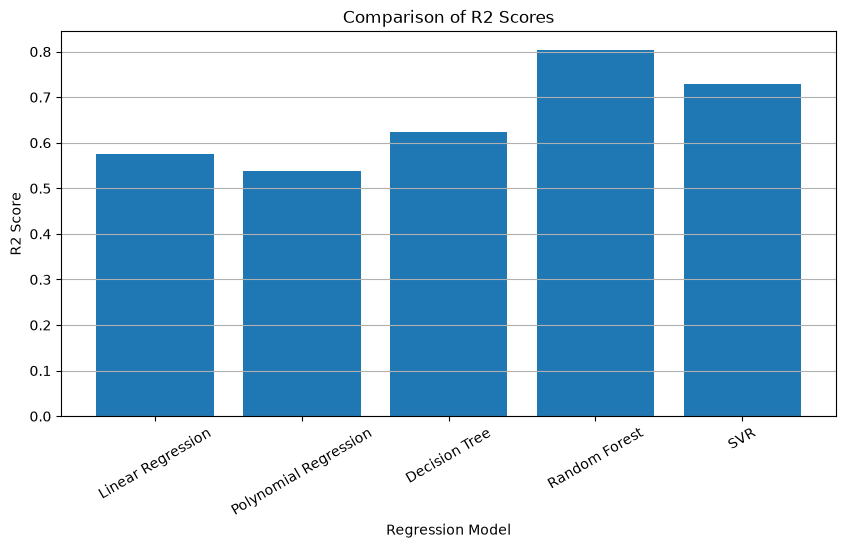

In [38]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df.index,
    results_df["R2 Score"]
)

plt.xlabel("Regression Model")
plt.ylabel("R2 Score")
plt.title("Comparison of R2 Scores")

plt.xticks(rotation=30)
plt.grid(axis='y')

plt.show()

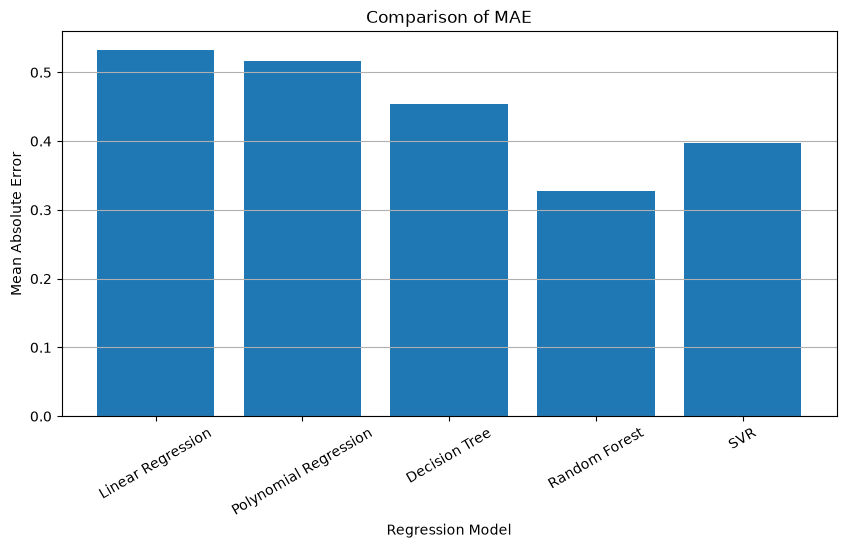

In [39]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df.index,
    results_df["MAE"]
)

plt.xlabel("Regression Model")
plt.ylabel("Mean Absolute Error")
plt.title("Comparison of MAE")

plt.xticks(rotation=30)
plt.grid(axis='y')

plt.show()

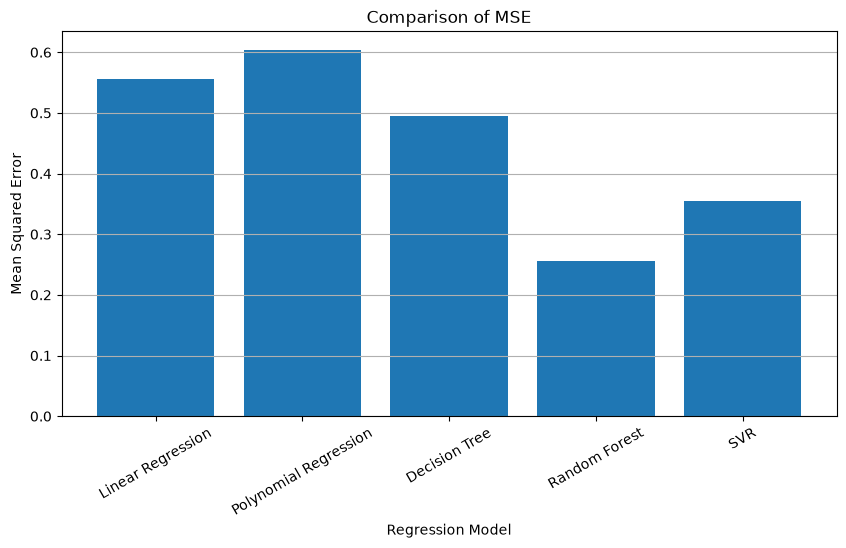

In [40]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df.index,
    results_df["MSE"]
)

plt.xlabel("Regression Model")
plt.ylabel("Mean Squared Error")
plt.title("Comparison of MSE")

plt.xticks(rotation=30)
plt.grid(axis='y')

plt.show()

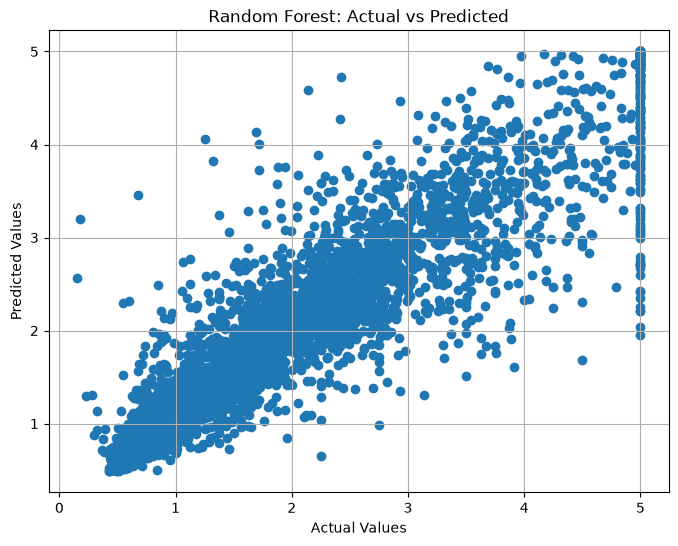

In [41]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_rf)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Random Forest: Actual vs Predicted")

plt.grid(True)

plt.show()

Dataset loaded successfully!
Dataset shape: (20640, 8)
Training samples: 16512
Testing samples: 4128


REGRESSION MODEL COMPARISON
                Model      MAE      MSE  R2 Score
    Linear Regression 0.533200 0.555892  0.575788
Polynomial Regression 0.516183 0.604538  0.538664
        Decision Tree 0.454171 0.494256  0.622823
        Random Forest 0.327731 0.256022  0.804624
                  SVR 0.397283 0.354151  0.729740

Best according to R2:
Random Forest

Best according to MAE:
Random Forest

Best according to MSE:
Random Forest


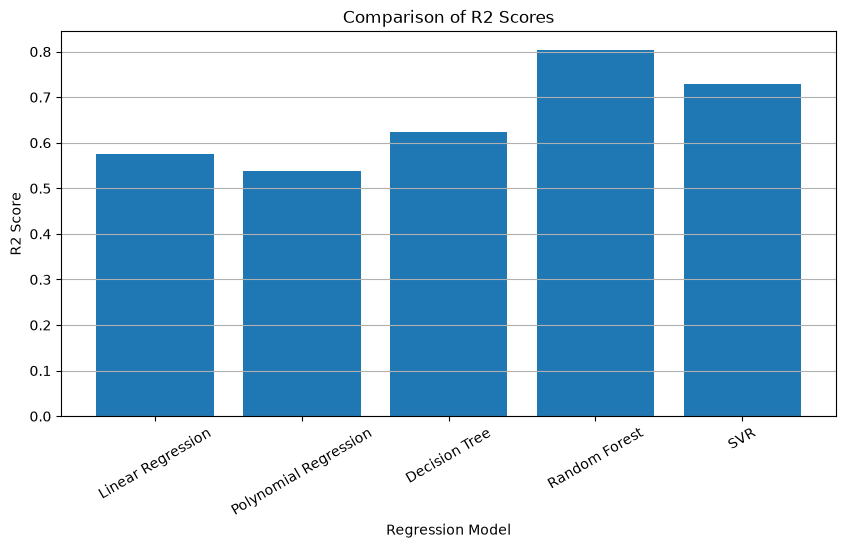

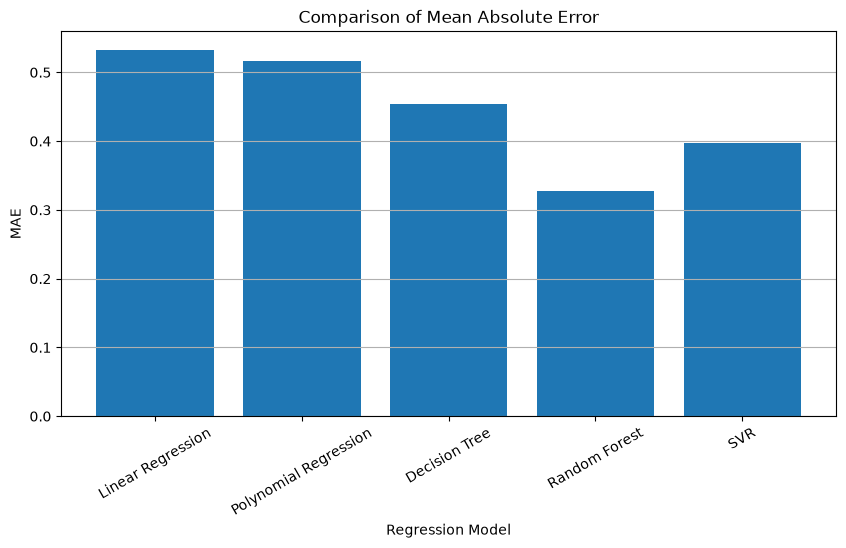

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ==========================================
# 1. LOAD DATASET
# ==========================================

from sklearn.datasets import fetch_california_housing

data = fetch_california_housing()

X = data.data
y = data.target

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)

# ==========================================
# 2. TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# ==========================================
# 3. FEATURE SCALING FOR SVR
# ==========================================

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(
    y_train.reshape(-1, 1)
).ravel()

# ==========================================
# 4. LINEAR REGRESSION
# ==========================================

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

# ==========================================
# 5. POLYNOMIAL REGRESSION
# ==========================================

poly = PolynomialFeatures(degree=2)

X_poly_train = poly.fit_transform(X_train)
X_poly_test = poly.transform(X_test)

poly_model = LinearRegression()

poly_model.fit(X_poly_train, y_train)

y_pred_poly = poly_model.predict(X_poly_test)

# ==========================================
# 6. DECISION TREE REGRESSION
# ==========================================

dt_model = DecisionTreeRegressor(
    random_state=42
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

# ==========================================
# 7. RANDOM FOREST REGRESSION
# ==========================================

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

# ==========================================
# 8. SUPPORT VECTOR REGRESSION
# ==========================================

svr_model = SVR(kernel='rbf')

svr_model.fit(
    X_train_scaled,
    y_train_scaled
)

y_pred_svr_scaled = svr_model.predict(X_test_scaled)

y_pred_svr = scaler_y.inverse_transform(
    y_pred_svr_scaled.reshape(-1, 1)
).ravel()

# ==========================================
# 9. EVALUATION FUNCTION
# ==========================================

def evaluate_model(name, y_true, y_pred):
    
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    return {
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "R2 Score": r2
    }

# ==========================================
# 10. EVALUATE ALL MODELS
# ==========================================

results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        y_pred_linear
    )
)

results.append(
    evaluate_model(
        "Polynomial Regression",
        y_test,
        y_pred_poly
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        y_pred_dt
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        y_pred_rf
    )
)

results.append(
    evaluate_model(
        "SVR",
        y_test,
        y_pred_svr
    )
)

# ==========================================
# 11. DISPLAY RESULTS
# ==========================================

results_df = pd.DataFrame(results)

print("\n")
print("=" * 70)
print("REGRESSION MODEL COMPARISON")
print("=" * 70)

print(results_df.to_string(index=False))

# ==========================================
# 12. FIND BEST MODELS
# ==========================================

best_r2 = results_df.loc[
    results_df["R2 Score"].idxmax()
]

best_mae = results_df.loc[
    results_df["MAE"].idxmin()
]

best_mse = results_df.loc[
    results_df["MSE"].idxmin()
]

print("\nBest according to R2:")
print(best_r2["Model"])

print("\nBest according to MAE:")
print(best_mae["Model"])

print("\nBest according to MSE:")
print(best_mse["Model"])

# ==========================================
# 13. R2 GRAPH
# ==========================================

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["R2 Score"]
)

plt.xlabel("Regression Model")
plt.ylabel("R2 Score")
plt.title("Comparison of R2 Scores")

plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()

# ==========================================
# 14. MAE GRAPH
# ==========================================

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["MAE"]
)

plt.xlabel("Regression Model")
plt.ylabel("MAE")
plt.title("Comparison of Mean Absolute Error")

plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()